# baebugs — sample → size → sieve plan
Replayable end-to-end run. **Swap data in the first code cell**: point `IMAGE` at a USB-camera photo
(or set `CAMERA`), set scale, and point `SIEVES` / `INSECTS` at your own YAML.
With everything `None` it runs on a synthetic tray with known ground truth.

Loop (mechanical scientific method): **observe → hypothesize → preflight → run → verify → update**.

In [1]:
# ---- swap your data here ----
IMAGE = None          # e.g. "data/tray_001.jpg"
CAMERA = None         # e.g. 0 for the USB microscope
PX_PER_MM = 40.0      # or None + ARUCO_MM
ARUCO_MM = None       # side length of printed ArUco marker in view
YOLO_WEIGHTS = None   # e.g. "weights/baebugs-seg.pt"; None = classical only
SIEVES = None         # path to sieves.yaml (None = package default ASTM stack)
INSECTS = None        # path to insects.yaml (None = placeholder classes)
SEED = 0

In [2]:
import sys, json, cv2, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from baebugs.measure import classical_measure, consensus, annotate, px_per_mm_from_aruco
from baebugs.sieve import load_yaml, plan_stack, classify
from baebugs.twin import LabTwin
from baebugs.method import verify, update_margin
from baebugs.synthetic import make_sample

truth = None
if IMAGE:
    img = cv2.imread(IMAGE)
elif CAMERA is not None:
    from baebugs.camera import capture; img = capture(CAMERA)
else:
    img, truth = make_sample(n=30, px_per_mm=PX_PER_MM, seed=SEED)
ppm = PX_PER_MM or px_per_mm_from_aruco(img, ARUCO_MM)
inv = load_yaml(SIEVES) if SIEVES else load_yaml("sieves.yaml")
ins = load_yaml(INSECTS) if INSECTS else load_yaml("insects.yaml")
print("px/mm:", ppm, "| image:", img.shape)

px/mm: 40.0 | image: (900, 1200, 3)


## 1 · Observe — two independent measurements + consensus

30 bodies, 0 flagged for review


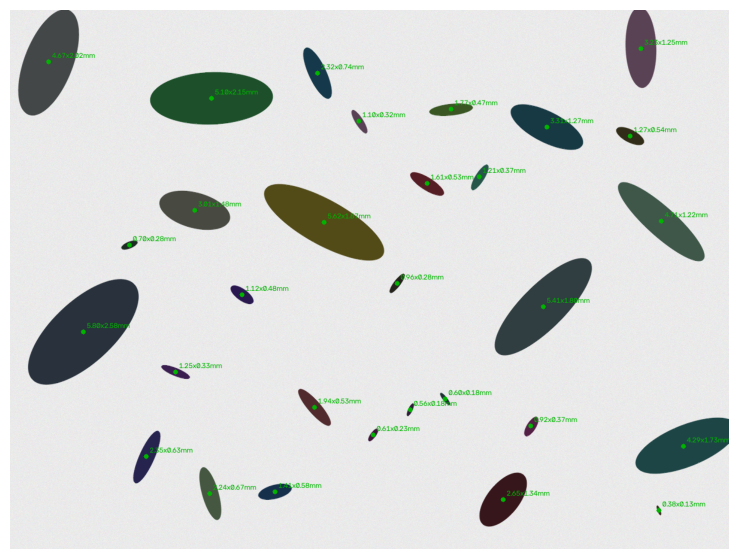

In [3]:
B = classical_measure(img, ppm)
if YOLO_WEIGHTS:
    from baebugs.measure import YoloMeasurer
    A = YoloMeasurer(YOLO_WEIGHTS)(img, ppm)
    ms = consensus(A, B, ppm)
else:
    ms = B
flagged = [m for m in ms if m.flag]
print(f"{len(ms)} bodies, {len(flagged)} flagged for review")
plt.figure(figsize=(10,7)); plt.imshow(cv2.cvtColor(annotate(img, ms), cv2.COLOR_BGR2RGB)); plt.axis("off");

median |error|  length 0.8%   width 2.4%
{'small': 12, 'medium': 12, 'large': 6, 'unclassified': 0}


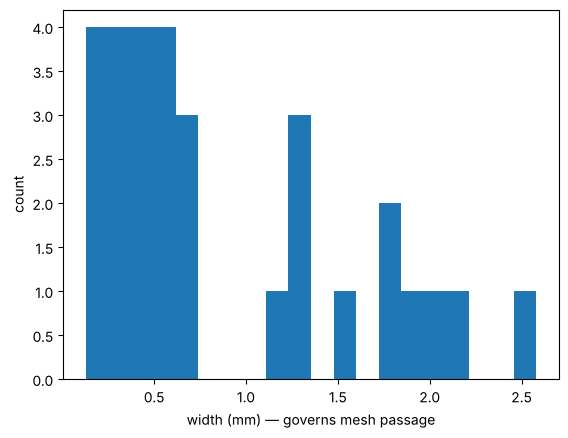

In [4]:
if truth:
    errs = []
    for t in truth:
        m = min(ms, key=lambda m: np.hypot(m.cx-t['cx'], m.cy-t['cy']))
        errs.append((m.length_mm/t['length_mm']-1, m.width_mm/t['width_mm']-1))
    e = np.array(errs)
    print(f"median |error|  length {np.median(abs(e[:,0])):.1%}   width {np.median(abs(e[:,1])):.1%}")
widths = [m.width_mm for m in ms if not m.flag]
plt.hist(widths, bins=20); plt.xlabel("width (mm) — governs mesh passage"); plt.ylabel("count");
print({c: sum(classify(w, ins['classes'])==c for w in widths) for c in [k['name'] for k in ins['classes']]+['unclassified']})

## 2 · Hypothesize — sieve stack + water flow

In [5]:
plan = plan_stack(widths, inv, ins)
print(json.dumps(plan.to_dict(), indent=2))

{
  "steps": [
    {
      "sieve_id": "S-16",
      "aperture_mm": 1.18,
      "slot": "A4",
      "purpose": "retain width >= 1.298 mm",
      "flow_l_per_min": 1.18,
      "rinse_l": 0.5,
      "expected_count": 8
    },
    {
      "sieve_id": "S-40",
      "aperture_mm": 0.425,
      "slot": "C1",
      "purpose": "retain width >= 0.468 mm",
      "flow_l_per_min": 0.425,
      "rinse_l": 0.5,
      "expected_count": 12
    },
    {
      "sieve_id": "S-200",
      "aperture_mm": 0.075,
      "slot": "C4",
      "purpose": "retain width >= 0.083 mm",
      "flow_l_per_min": 0.25,
      "rinse_l": 0.5,
      "expected_count": 10
    }
  ],
  "passthrough_expected": 0,
  "water_l": 1.5,
  "notes": [
    "no sieve fine enough to retain width >= 0.080 mm"
  ]
}


## 3 · Preflight against the lab twin (nothing reaches the arm unless this is clean)

In [6]:
twin = LabTwin(inv, log_path="../runs/notebook_actions.jsonl")
errs = twin.preflight(plan)
print("preflight:", errs or "OK")
if not errs:
    twin.execute(plan, robot=None, dry_run=True)   # pass a RobotAdapter + dry_run=False on the bench
    print("water left:", round(twin.state['water']['reservoir_l'], 2), "L")

preflight: OK
water left: 3.5 L


## 4 · Verify & update
After the run, image each sieve's fraction and count it (re-run section 1 per fraction).
Here we simulate the bench retaining a little more than predicted on the top sieve.

In [7]:
observed = {s.sieve_id: s.expected_count for s in plan.steps}
if plan.steps: observed[plan.steps[0].sieve_id] += 2   # <- replace with real counts
v = verify(plan, observed, observed_passthrough=plan.passthrough_expected)
for x in v: print(f"{x.sieve_id:6s} predicted {x.predicted:3d} observed {x.observed:3d} error {x.error:+d}")
new_margin = update_margin(ins['retention_margin'], v)
print("retention_margin:", ins['retention_margin'], "->", round(new_margin, 3))
twin.release(plan)

S-16   predicted   8 observed  10 error +2
S-40   predicted  12 observed  12 error +0
S-200  predicted  10 observed  10 error +0
drain  predicted   0 observed   0 error +0
retention_margin: 1.1 -> 1.086
